<a href="https://colab.research.google.com/github/ritika-adk/AI_Ml-BootCamp/blob/main/california_house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


California Housing Price Prediction

## Objective
The objective of this project is to predict median house values in California using machine learning regression algorithms.

## Models
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score


In [35]:

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [22]:

# 2. LOAD DATASET

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [23]:

# 3. BASIC EDA

print("Missing Values:\n")
print(df.isnull().sum())

print("\nSummary Statistics:\n")
display(df.describe())


Missing Values:

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Summary Statistics:



,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


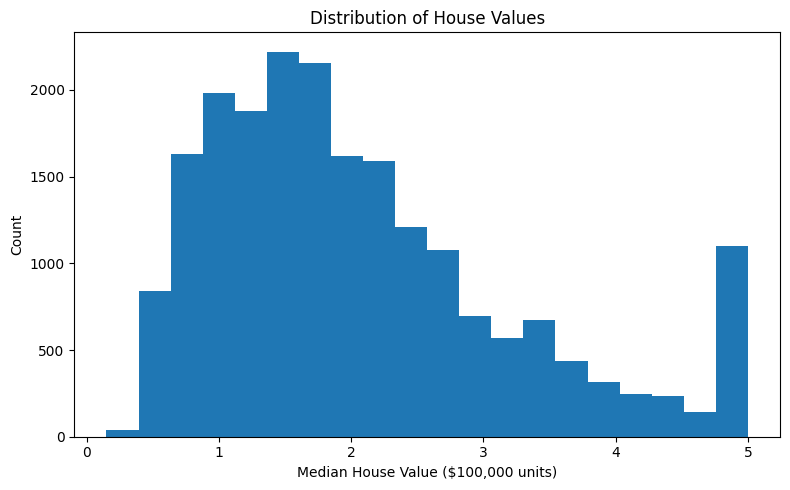

In [24]:

# 4A. TARGET DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df["MedHouseVal"], bins=20)

plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Count")
plt.title("Distribution of House Values")

plt.tight_layout()
plt.savefig("eda_target_distribution.png")
plt.show()


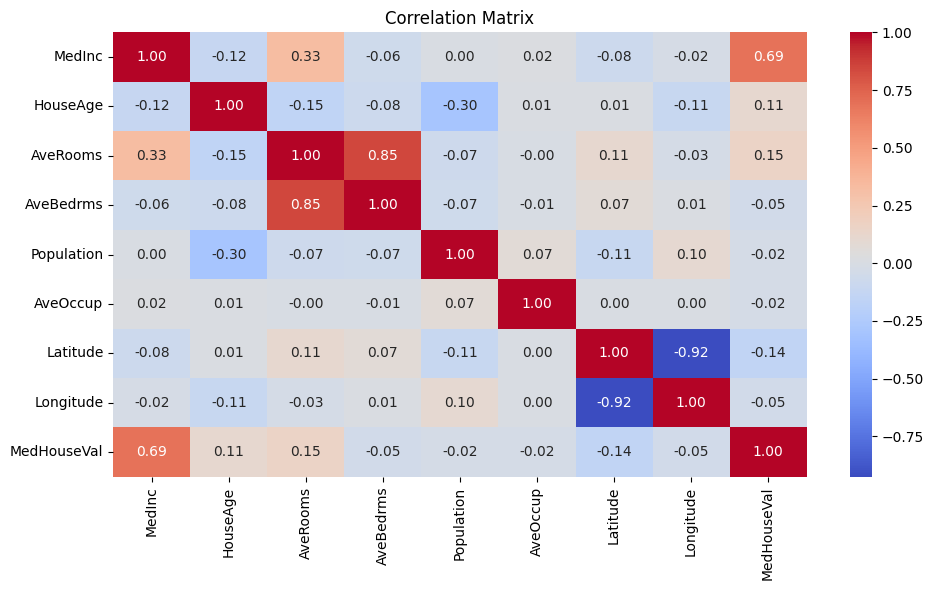

In [25]:

# 4B. CORRELATION HEATMAP

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("eda_correlation.png")
plt.show()


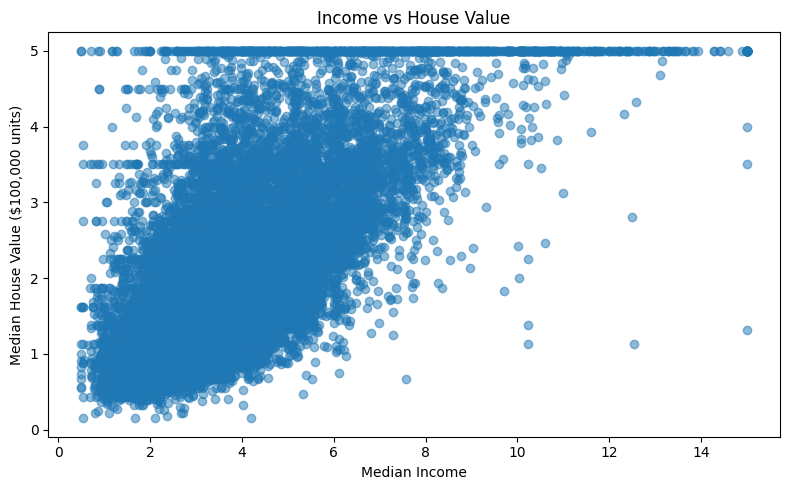

In [26]:

# 4C. SCATTER PLOT: INCOME VS PRICE

plt.figure(figsize=(8, 5))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.5
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("Income vs House Value")

plt.tight_layout()
plt.show()


In [27]:

# 5. FEATURE ENGINEERING

df["rooms_per_household"] = df["AveRooms"] / df["AveOccup"]

df["bedroom_ratio"] = df["AveBedrms"] / df["AveRooms"]

df["population_per_household"] = (
    df["Population"] / df["AveOccup"]
)

# Approximate geographic distance from Los Angeles and San Francisco
LA_lat, LA_lon = 34.05, -118.24
SF_lat, SF_lon = 37.77, -122.42

df["dist_to_LA"] = np.sqrt(
    (df["Latitude"] - LA_lat) ** 2
    + (df["Longitude"] - LA_lon) ** 2
)

df["dist_to_SF"] = np.sqrt(
    (df["Latitude"] - SF_lat) ** 2
    + (df["Longitude"] - SF_lon) ** 2
)

print("Feature engineering completed!")
print("Updated dataset shape:", df.shape)

display(df.head())


Feature engineering completed!
Updated dataset shape: (20640, 14)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,rooms_per_household,bedroom_ratio,population_per_household,dist_to_LA,dist_to_SF
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,2.732919,0.146591,126.0,5.530732,0.219545
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,2.956685,0.155797,1138.0,5.509673,0.219317
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,2.957661,0.129516,177.0,5.517246,0.196977
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,2.283154,0.184458,219.0,5.524500,0.187883
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,2.879646,0.172096,259.0,5.524500,0.187883


In [28]:

# 6. OUTLIER HANDLING

for col in ["AveRooms", "AveOccup", "AveBedrms"]:
    cap = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=cap)

print("Outlier capping completed!")


Outlier capping completed!


In [29]:

# 7. TRAIN-TEST SPLIT

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 13)
Testing features: (4128, 13)
Training target: (16512,)
Testing target: (4128,)


In [30]:

# 8. MODELS

# Linear Regression with feature scaling
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

# Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)

# Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)

print("All three models are ready!")


All three models are ready!


In [31]:

# 9. TRAIN MODELS

print("Training Linear Regression...")
lr_model.fit(X_train, y_train)

print("Training Decision Tree...")
dt_model.fit(X_train, y_train)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("All models trained successfully!")


Training Linear Regression...
Training Decision Tree...
Training Random Forest...
All models trained successfully!


In [32]:

# 10. PREDICTIONS

y_pred_lr = lr_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("Linear Regression predictions:")
print(y_pred_lr[:5])

print("\nDecision Tree predictions:")
print(y_pred_dt[:5])

print("\nRandom Forest predictions:")
print(y_pred_rf[:5])

print("\nActual house values:")
print(y_test.iloc[:5].to_numpy())


Linear Regression predictions:
[0.41198478 1.91889078 3.25918394 2.70698099 2.68813734]

Decision Tree predictions:
[0.517   0.521   5.00001 1.773   2.257  ]

Random Forest predictions:
[0.47529   0.72525   4.8870655 2.45404   2.32241  ]

Actual house values:
[0.477   0.458   5.00001 2.186   2.78   ]


In [33]:

# 11. EVALUATION FUNCTION

def evaluate_model(name, y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    print(f"\n{name}")
    print("-" * 35)
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


In [34]:

# 12. MODEL COMPARISON

results = []

results.append(
    evaluate_model("Linear Regression", y_test, y_pred_lr)
)

results.append(
    evaluate_model("Decision Tree", y_test, y_pred_dt)
)

results.append(
    evaluate_model("Random Forest", y_test, y_pred_rf)
)

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df.sort_values(by="R2", ascending=False))



Linear Regression
-----------------------------------
MAE  : 0.4881
RMSE : 0.6715
R²   : 0.6559

Decision Tree
-----------------------------------
MAE  : 0.4467
RMSE : 0.7170
R²   : 0.6077

Random Forest
-----------------------------------
MAE  : 0.3100
RMSE : 0.4850
R²   : 0.8205

Model Comparison:


,Model,MAE,RMSE,R2
2,Random Forest,0.310024,0.484977,0.820512
0,Linear Regression,0.488117,0.671548,0.655851
1,Decision Tree,0.446738,0.717020,0.607666


In [15]:

# 13. HYPERPARAMETER TUNING

rf = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R²:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation R²:
0.8178


In [16]:

# 14. CROSS-VALIDATION

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validation R² scores:", cv_scores)
print(f"Mean CV R²: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")


Cross-validation R² scores: [0.8240764  0.80615832 0.82075125 0.81631118 0.82163435]
Mean CV R²: 0.8178
Standard Deviation: 0.0063


In [17]:

# FINAL TEST EVALUATION

y_pred = best_model.predict(X_test)

final_results = evaluate_model(
    "Tuned Random Forest",
    y_test,
    y_pred
)



Tuned Random Forest
-----------------------------------
MAE  : 0.3100
RMSE : 0.4850
R²   : 0.8205


Feature Importance:


,Feature,Importance
0,MedInc,0.510905
5,AveOccup,0.118386
12,dist_to_SF,0.069184
6,Latitude,0.058480
11,dist_to_LA,0.051219
7,Longitude,0.040811
1,HouseAge,0.040681
8,rooms_per_household,0.027193
9,bedroom_ratio,0.019986
3,AveBedrms,0.018487


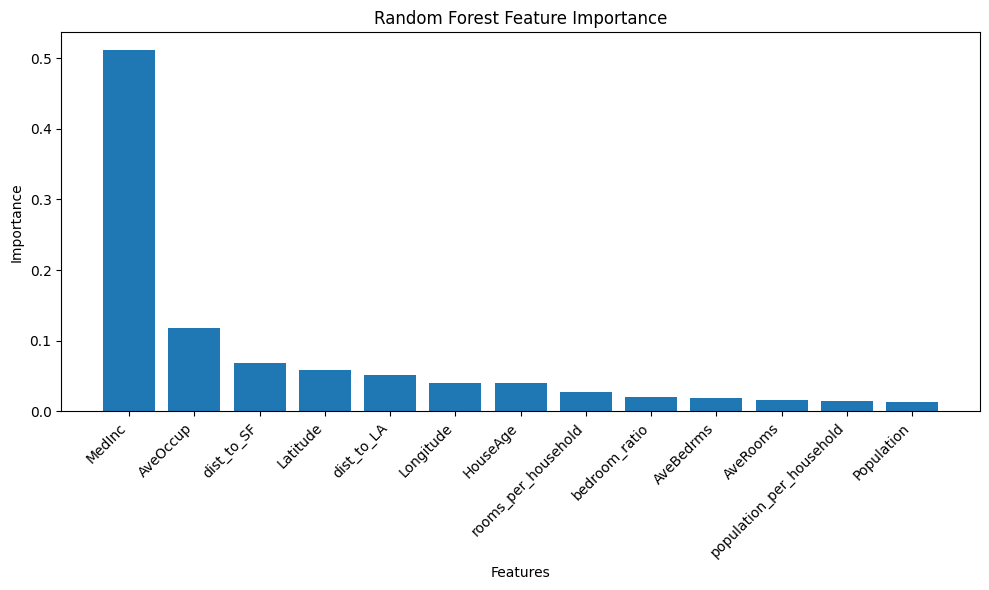

In [18]:

# 15. FEATURE IMPORTANCE

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance)

plt.figure(figsize=(10, 6))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()


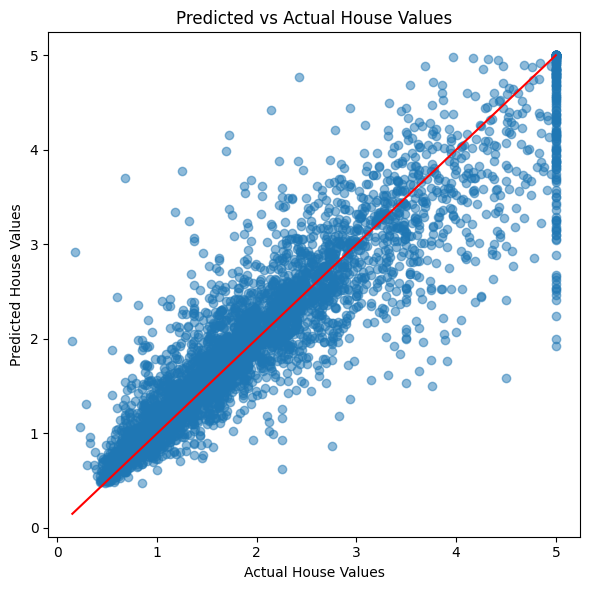

In [19]:

# 16. PREDICTED VS ACTUAL

plt.figure(figsize=(6, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Predicted vs Actual House Values")

# Reference line: perfect predictions
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    color="red"
)

plt.tight_layout()
plt.show()


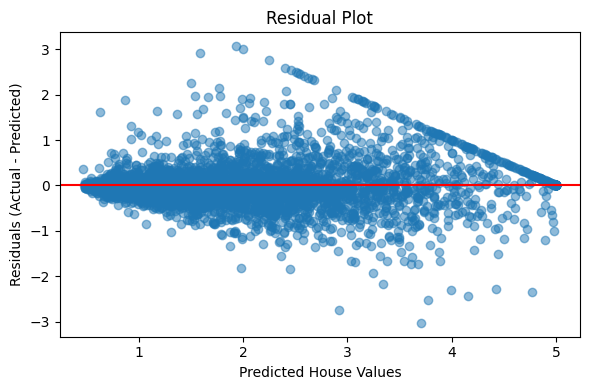

In [20]:

# 17. RESIDUAL PLOT

residuals = y_test - y_pred

plt.figure(figsize=(6, 4))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")

plt.tight_layout()
plt.show()
